# 06 - Monitoring: when would we have retrained?

A model is a claim about a population, and populations move. This notebook runs
the drift module month by month on a **simulated** year in which prices creep up,
more customers move to month-to-month contracts, and churn rises for a reason the
model cannot see (a competitor launch).

The point is not the specific month. It is that the trigger defined in
`telco_churn.drift` is executable: it produces a date, a cause and an owner, which
is what a monitoring process needs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import expit, logit

from telco_churn.data import load_clean
from telco_churn.drift import PSI_ALERT, drift_report, should_retrain
from telco_churn.evaluate import summary_metrics
from telco_churn.features import FEATURES, train_test
from telco_churn.model import build_pipeline

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(11)

df = load_clean()
X_train, X_test, y_train, y_test = train_test(df, seed=42)
pipe = build_pipeline("logistic", seed=42).fit(X_train, y_train)
reference = X_train.reset_index(drop=True)
brier_ref = summary_metrics(y_test, pipe.predict_proba(X_test)[:, 1])["brier"]
print(f"Reference Brier on the holdout: {brier_ref:.4f}")

Reference Brier on the holdout: 0.1479


## Simulating a year of drift

Each month draws 1,000 customers from the holdout, then applies two observable
changes (prices +1% per month, contract mix shifting to month-to-month) and one
unobservable change (churn probability rising by 0.10 on the log-odds scale per
month). The unobservable shift is what makes the Brier score deteriorate; the
observable shifts are what PSI can see.

In [2]:
rows = []
snapshots = {}
for month in range(1, 13):
    snap = X_test.sample(n=1000, replace=True, random_state=month).reset_index(drop=True)
    snap["MonthlyCharges"] = snap["MonthlyCharges"] * (1 + 0.01 * month)
    flip = RNG.random(len(snap)) < 0.02 * month
    snap.loc[flip, "Contract"] = "Month-to-month"

    p = pipe.predict_proba(snap[FEATURES])[:, 1]
    # True outcome: the model's log-odds plus an unobserved monthly deterioration.
    y_true = RNG.binomial(1, expit(logit(np.clip(p, 1e-6, 1 - 1e-6)) + 0.10 * month))

    report = drift_report(reference, snap)
    retrain, reason = should_retrain(report, brier_now=summary_metrics(y_true, p)["brier"],
                                     brier_ref=brier_ref)
    rows.append({
        "month": month,
        "brier": summary_metrics(y_true, p)["brier"],
        "max_psi": report["psi"].max(),
        "worst_feature": report.loc[0, "feature"],
        "features_flagged": int(report["flag"].sum()),
        "retrain": retrain,
        "reason": reason,
    })
    snapshots[month] = report

monitor = pd.DataFrame(rows)
monitor.round(3).head(12)

,month,brier,max_psi,worst_feature,features_flagged,retrain,reason
0,1,0.149,0.036,MonthlyCharges,0,False,no trigger met
1,2,0.153,0.073,MonthlyCharges,0,False,no trigger met
2,3,0.146,0.166,MonthlyCharges,0,False,no trigger met
3,4,0.154,0.255,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
4,5,0.161,0.307,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
5,6,0.179,0.311,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
6,7,0.173,0.451,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
7,8,0.171,1.123,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
8,9,0.182,0.397,MonthlyCharges,1,True,1 features drifted (PSI above threshold)
9,10,0.200,1.186,MonthlyCharges,1,True,1 features drifted (PSI above threshold)


## The two signals

PSI catches the observable part; Brier catches the part that matters. The
documented trigger fires on either: any feature above PSI 0.2, or Brier worsening
by more than 0.02.

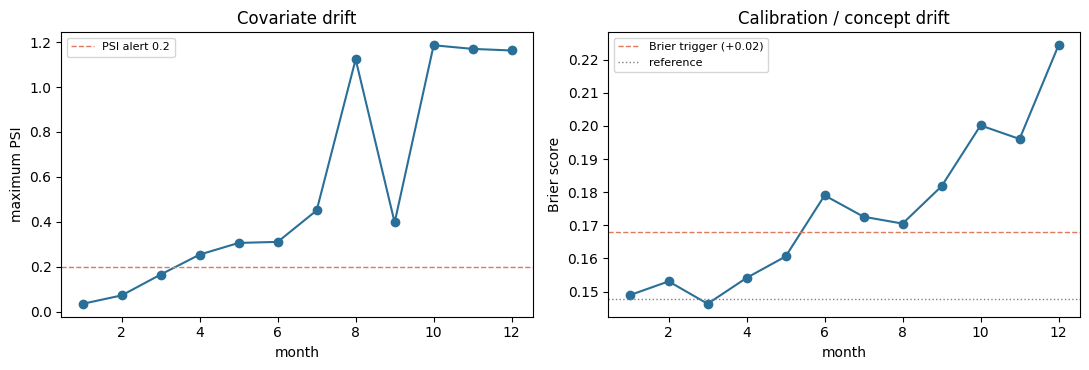

First trigger: month 4 - 1 features drifted (PSI above threshold)
Worst feature then: MonthlyCharges (PSI 0.25)
Brier: 0.154 vs reference 0.148


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(monitor.month, monitor.max_psi, marker="o", color="#2a6f97")
axes[0].axhline(PSI_ALERT, color="#e07a5f", ls="--", lw=1, label="PSI alert 0.2")
axes[0].set_xlabel("month"); axes[0].set_ylabel("maximum PSI")
axes[0].set_title("Covariate drift")
axes[0].legend(fontsize=8)

axes[1].plot(monitor.month, monitor.brier, marker="o", color="#2a6f97")
axes[1].axhline(brier_ref + 0.02, color="#e07a5f", ls="--", lw=1, label="Brier trigger (+0.02)")
axes[1].axhline(brier_ref, color="grey", ls=":", lw=1, label="reference")
axes[1].set_xlabel("month"); axes[1].set_ylabel("Brier score")
axes[1].set_title("Calibration / concept drift")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "06_monitoring.png", dpi=140)
plt.show()

first = monitor.loc[monitor.retrain].head(1)
if len(first):
    row = first.iloc[0]
    print(f"First trigger: month {int(row.month)} - {row.reason}")
    print(f"Worst feature then: {row.worst_feature} (PSI {row.max_psi:.2f})")
    print(f"Brier: {row.brier:.3f} vs reference {brier_ref:.3f}")
else:
    print("No trigger in the simulated year.")

## What the report looks like on the triggering month

The value of the report is that it names the feature and the direction, so the
review has somewhere to start.

In [4]:
trigger_month = int(monitor.loc[monitor.retrain, "month"].min()) if monitor.retrain.any() else 12
print(f"Drift report for month {trigger_month}:")
snapshots[trigger_month].head(6).round(3)

Drift report for month 4:


,feature,psi,flag
0,MonthlyCharges,0.255,True
1,Contract,0.008,False
2,OnlineBackup,0.005,False
3,Partner,0.004,False
4,PaperlessBilling,0.003,False
5,StreamingTV,0.002,False


## How this would be used

1. **Monthly**, score recent customers and compute PSI against the training
   reference. This needs no labels.
2. **Quarterly** (or when labels arrive), compute Brier on matured outcomes. This
   is the signal that actually matters, and it lags.
3. When the trigger fires, the review is owned by the model's data scientist
   within one week. The first question is whether the change is a fixable data
   issue (a new category, a pricing migration) or genuine concept drift.
4. Prefer recalibration before retraining if the ranking is intact and only the
   level moved. Retrain when the ranking itself has degraded.

## Limitations

- The year is simulated. It demonstrates the mechanics, not the real drift rate of
  this business.
- PSI is univariate, so it misses interactions and changes in the relationship
  between features and outcome.
- Label lag is the hard part in production: churn outcomes arrive months after the
  prediction, which is why the unlabelled PSI signal exists.